# Chapter 11 — Outlier and Novelty Detection

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Hampir setiap dataset nyata mengandung pengamatan yang "tidak biasa": transaksi kartu kredit yang mencurigakan, pembacaan sensor yang melonjak, atau sekadar salah ketik saat input data. Titik-titik seperti ini bisa merusak model (mis. menarik garis regresi atau menggeser pusat cluster), tetapi bisa juga justru menjadi hal yang paling ingin kita temukan (fraud, kerusakan mesin, serangan jaringan). Chapter ini membahas dua masalah yang berkaitan namun berbeda: **outlier detection** (data latih sudah "terkontaminasi" anomali, dan kita ingin menandainya) dan **novelty detection** (data latih bersih, lalu kita menilai apakah data *baru* termasuk distribusi yang sama). Algoritma utama yang dipakai adalah **Isolation Forest**, **One-Class SVM**, dan **Local Outlier Factor (LOF)**, ditambah cara mengevaluasi detektor, menangani outlier yang sudah ditemukan, dan memilih metode yang tepat.

**Daftar Isi**

1. 11.1 Pengantar Outlier dan Novelty Detection
2. 11.2 Isolation Forest
3. 11.3 One-Class SVM untuk Novelty Detection
4. 11.4 Local Outlier Factor (LOF)
5. 11.5 Evaluasi Model Deteksi Outlier
6. 11.6 Penanganan Outlier yang Terdeteksi
7. 11.7 Memilih Teknik Deteksi yang Tepat
8. Latihan (Exercise 1–3: Isolation Forest, LOF, One-Class SVM)
9. Ringkasan Chapter 11

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 11 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 / pandas 3.1 dan reprodusibel (penambahan `np.random.seed`), lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**). Semua data dibangkitkan dengan `sklearn.datasets.make_blobs` (data sintetis bawaan scikit-learn). Beberapa kekeliruan kecil pada kode asli (warna plot tertukar di One-Class SVM, data uji "normal" yang berasal dari distribusi lain, dan tanda skor ROC-AUC yang terbalik) diperbaiki dan dijelaskan di tempatnya.

## Import Library

In [1]:
%matplotlib inline
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)
from IPython.display import display

plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('python       :', sys.version.split()[0])
print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)

python       : 3.12.15
numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1


## 11.1 Pengantar Outlier dan Novelty Detection

**Teori:**

**Apa itu anomali?** Hawkins (1980) mendefinisikan outlier sebagai *"pengamatan yang menyimpang begitu jauh dari pengamatan lain sehingga menimbulkan kecurigaan bahwa ia dibangkitkan oleh mekanisme yang berbeda"*. Secara probabilistik, kita menganggap data berasal dari campuran

$$
p(x) = (1-\varepsilon)\,p_{\text{normal}}(x) + \varepsilon\,p_{\text{anomali}}(x),
$$

dengan $\varepsilon$ kecil (proporsi kontaminasi). Tugas detektor adalah memberi setiap titik sebuah **skor anomali** $s(x)$ — makin besar makin janggal — lalu memotongnya dengan ambang $\tau$: titik dengan $s(x) > \tau$ dianggap anomali.

**Outlier detection vs novelty detection** (istilah resmi dokumentasi scikit-learn):

| | Outlier detection | Novelty detection |
|---|---|---|
| Data latih | sudah mengandung anomali (*contaminated*) | bersih, hanya data normal |
| Pertanyaan | "titik mana di data ini yang janggal?" | "apakah titik *baru* ini mirip data latih?" |
| Sifat | unsupervised, transduktif | semi-supervised, induktif |
| Contoh estimator | `IsolationForest`, `LocalOutlierFactor` (default), `EllipticEnvelope` | `OneClassSVM`, `LocalOutlierFactor(novelty=True)` |

**API bersama scikit-learn.** Semua detektor mengikuti konvensi yang sama:

- `fit(X)` mempelajari "wilayah normal"; `predict(X)` mengembalikan **+1 untuk inlier dan −1 untuk outlier** (bukan 0/1!).
- `score_samples(X)`: skor kenormalan mentah (makin besar makin normal).
- `decision_function(X) = score_samples(X) − offset_`; ambang keputusan berada di **0**, nilai negatif = outlier.
- `contamination` (untuk IsolationForest/LOF/EllipticEnvelope) menentukan `offset_` sebagai **persentil** skor data latih, sehingga tepat ~`contamination`×n titik latih ditandai outlier. Artinya parameter ini **tidak** mengubah skor, hanya ambangnya.

**Mengapa sulit?** (1) Label anomali jarang tersedia, sehingga ambang dan hiperparameter sulit dituning; (2) anomali sangat langka sehingga metrik seperti akurasi menyesatkan; (3) definisi "normal" bergantung konteks (global vs lokal); (4) pada dimensi tinggi jarak antar titik cenderung seragam (*curse of dimensionality*), sehingga metode berbasis jarak/kepadatan melemah.

Resep pembuka buku langsung mendemonstrasikan LOF (dibahas detail di 11.4) pada satu cluster Gaussian yang dicemari 20 titik acak seragam.

Pusat cluster normal  : [1.758 3.98 ]
Std per fitur (normal): [0.615 0.637]
Ukuran data gabungan  : (320, 2)


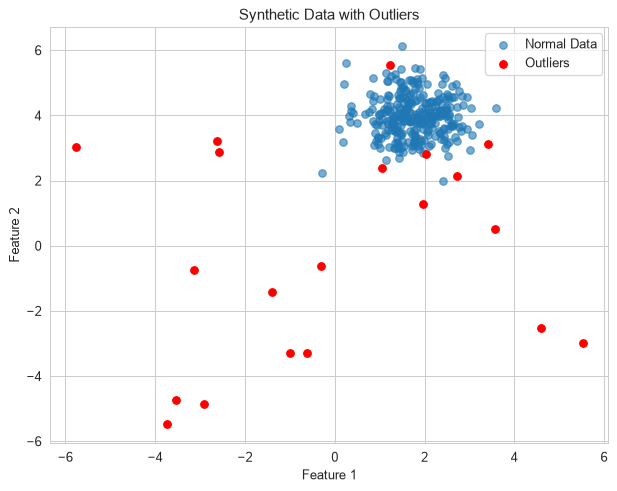

In [2]:
# Dataset sintetis: satu cluster normal (300 titik) + 20 outlier acak seragam di [-6, 6]^2
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

print('Pusat cluster normal  :', X.mean(axis=0).round(3))
print('Std per fitur (normal):', X.std(axis=0).round(3))
print('Ukuran data gabungan  :', X_with_outliers.shape)

# Visualisasi data dengan outlier
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Cluster normal berpusat di sekitar **(1.76, 3.98)** dengan simpangan baku ~**0.62** per fitur, sedangkan 20 outlier tersebar seragam pada kotak $[-6,6]^2$ yang jauh lebih luas. Total ada 320 titik dengan proporsi kontaminasi sebenarnya $20/320 = 6.25\%$.
- Secara visual sebagian besar titik merah jelas berada di luar cluster, tetapi karena distribusinya seragam, beberapa titik merah kebetulan jatuh dekat cluster — titik-titik inilah yang nantinya sulit dideteksi oleh metode apa pun.

Jumlah titik ditandai outlier : 16 dari 320
...yang memang outlier sintetis: 15 dari 20


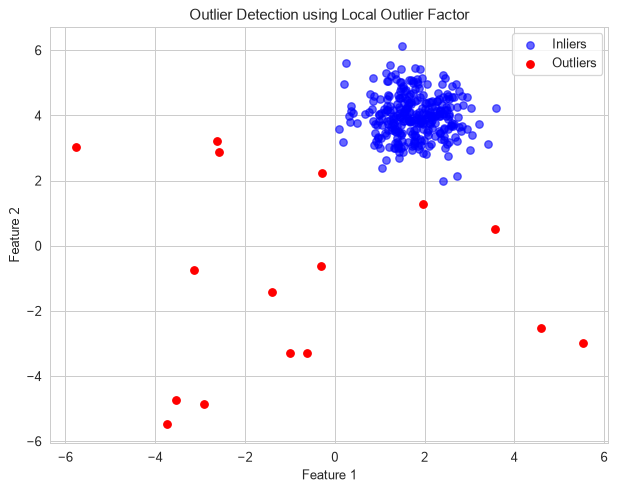

In [3]:
# LOF sebagai detektor outlier (unsupervised, fit + predict sekaligus)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)   # +1 = inlier, -1 = outlier

# Label sebenarnya (hanya untuk mengecek; LOF tidak melihatnya)
y_true_1 = np.r_[np.zeros(len(X)), np.ones(len(outliers))]
flag = (y_pred == -1)
print('Jumlah titik ditandai outlier :', flag.sum(), 'dari', len(flag))
print('...yang memang outlier sintetis:', int((flag & (y_true_1 == 1)).sum()), 'dari', len(outliers))

# Plot prediksi
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Dengan `contamination=0.05`, LOF menandai tepat $\lceil 0.05\times320\rceil = $ **16** titik sebagai outlier — angka ini ditentukan oleh `contamination`, bukan oleh data. Dari 16 titik itu, **15** memang outlier sintetis (presisi ≈ 94%), sementara 5 dari 20 outlier lolos (recall 75%).
- Recall tidak bisa 100% karena kita memberi kuota 5% (16 titik) padahal outlier sebenarnya 6.25% (20 titik); selain itu outlier yang jatuh dekat/di dalam cluster memang tidak tampak janggal. Ini menegaskan pentingnya memilih `contamination` mendekati proporsi anomali yang sebenarnya, atau bekerja langsung dengan skor kontinu.

## 11.2 Isolation Forest

**Teori:**

**Ide dasar (Liu, Ting & Zhou, 2008).** Alih-alih memodelkan seperti apa data normal, Isolation Forest **mengisolasi** setiap titik dengan pemotongan acak. Anomali itu "sedikit dan berbeda", sehingga mereka terisolasi dengan **sedikit potongan**, sedangkan titik di tengah kerumunan butuh banyak potongan.

**Isolation tree (iTree).** Dari subsampel acak berukuran $\psi$ (default `max_samples='auto'` = $\min(256, n)$), pohon dibangun rekursif: pilih satu fitur $q$ secara acak, pilih ambang $p$ secara seragam di antara $[\min x_q, \max x_q]$ pada node tersebut, bagi data menjadi $x_q<p$ dan $x_q\ge p$, ulangi sampai node berisi satu titik atau tinggi pohon mencapai $\lceil\log_2\psi\rceil$. Panjang lintasan $h(x)$ adalah jumlah sisi dari akar sampai daun tempat $x$ jatuh.

**Normalisasi dan skor anomali.** Rata-rata panjang lintasan pencarian gagal pada *binary search tree* dengan $n$ titik adalah

$$
c(n) = 2H(n-1) - \frac{2(n-1)}{n}, \qquad H(i)\approx \ln i + 0.5772 \ (\text{konstanta Euler}).
$$

Skor anomali untuk ensemble $T$ pohon:

$$
s(x,\psi) = 2^{-\,\mathbb{E}[h(x)]/c(\psi)} .
$$

- $\mathbb{E}[h(x)] \to 0 \Rightarrow s\to 1$: hampir pasti anomali.
- $\mathbb{E}[h(x)] \approx c(\psi) \Rightarrow s\approx 0.5$: tidak ada anomali yang jelas.
- $\mathbb{E}[h(x)] \to \psi-1 \Rightarrow s\to 0$: sangat normal.

Di scikit-learn, `score_samples(x)` $= -s(x)$ dan `decision_function` $= -s(x) - \texttt{offset\_}$. Dengan `contamination='auto'`, `offset_` = −0.5 (ambang paper); dengan nilai numerik, `offset_` dipilih sebagai persentil skor data latih.

**Mengapa efisien.** Kompleksitas latih $O(T\,\psi\log\psi)$ — tidak bergantung $n$ karena memakai subsampel — dan prediksi $O(nT\log\psi)$. Tidak ada perhitungan jarak, sehingga relatif tahan terhadap dimensi tinggi dan skala fitur (pemotongan dilakukan per fitur). Subsampling kecil juga mengurangi efek *swamping* (normal dikira anomali) dan *masking* (anomali bergerombol saling menutupi).

**Kelemahan.** Potongan selalu sejajar sumbu, sehingga peta skor memiliki artefak berbentuk "salib" di sepanjang sumbu (diatasi varian *Extended Isolation Forest*); IF juga bersifat **global**, sehingga kurang peka pada anomali lokal di antara cluster dengan kepadatan berbeda (lihat 11.4).

**Hiperparameter penting:** `n_estimators` (100 biasanya cukup — skor konvergen cepat), `max_samples`, `contamination`, `max_features`, dan `random_state` (algoritmanya acak).

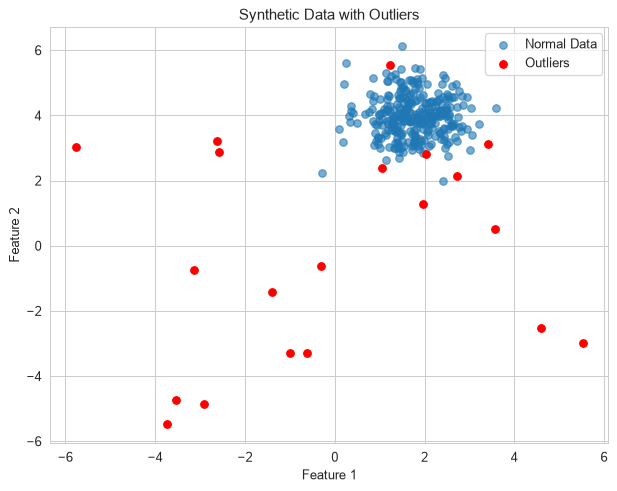

In [4]:
# Data yang sama seperti 11.1 (cluster normal + 20 outlier seragam)
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

Data identik dengan 11.1 (seed yang sama), sehingga kita bisa membandingkan langsung IF dengan LOF: satu cluster padat berpusat di (1.76, 3.98) dan 20 titik merah tersebar di kotak $[-6,6]^2$.

max_samples efektif (psi)      : 256
offset_ (ambang decision)      : -0.5912
Jumlah titik ditandai outlier  : 16
...yang memang outlier sintetis: 14 dari 20
ROC-AUC (skor kontinu)         : 0.9878


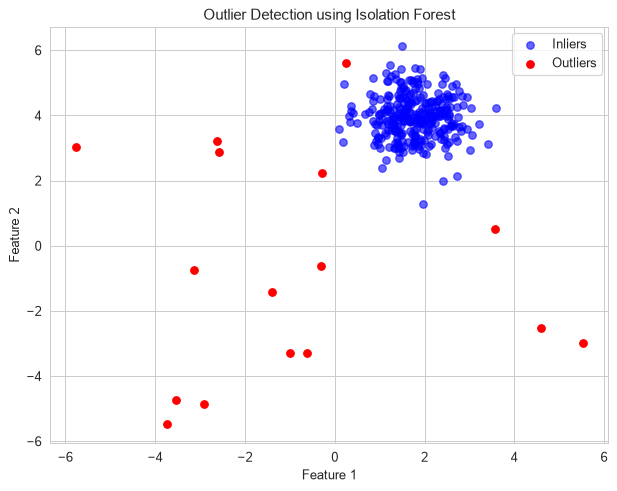

In [5]:
# Isolation Forest: 100 pohon isolasi, ekspektasi 5% outlier
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)
model.fit(X_combined)
y_pred = model.predict(X_combined)

y_true_2 = np.r_[np.zeros(len(X)), np.ones(len(outliers))]
flag = (y_pred == -1)
print('max_samples efektif (psi)      :', model.max_samples_)
print('offset_ (ambang decision)      :', round(model.offset_, 4))
print('Jumlah titik ditandai outlier  :', flag.sum())
print('...yang memang outlier sintetis:', int((flag & (y_true_2 == 1)).sum()), 'dari', len(outliers))
print('ROC-AUC (skor kontinu)         :', round(roc_auc_score(y_true_2, -model.score_samples(X_combined)), 4))

plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0], X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0], X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Setiap pohon dibangun dari subsampel $\psi = $ **256** titik (min(256, 320)). `offset_` = **−0.591**, artinya titik dengan skor anomali $s(x) > 0.591$ ditandai outlier — sedikit di atas ambang teoritis 0.5 karena kuota `contamination=0.05` memaksa hanya 5% teratas yang ditandai.
- IF menandai **16** titik, **14** di antaranya outlier sintetis (presisi 87.5%, recall 70%) — sedikit di bawah LOF pada 11.1 (15 benar). Namun **ROC-AUC skor kontinunya 0.988**, artinya peringkat skornya hampir sempurna; kesalahan terutama berasal dari ambang/kuota, bukan dari kualitas skor.
- Pada plot, titik merah di luar cluster tertangkap, sementara beberapa outlier yang jatuh dekat cluster tetap biru.

*Tambahan (bukan bagian dari notebook asli):* peta skor anomali $s(x)$ di seluruh bidang beserta garis ambang `decision_function = 0`, untuk melihat bentuk "wilayah normal" yang dipelajari Isolation Forest.

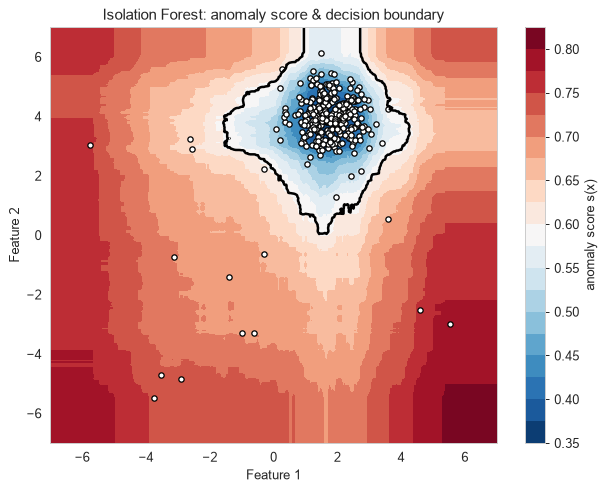

Rata-rata skor anomali  inlier : 0.399
Rata-rata skor anomali outlier : 0.651
Ambang skor (= -offset_)       : 0.591


In [6]:
# Peta skor anomali s(x) = -score_samples(x) di seluruh bidang + garis ambang (decision_function = 0)
xx, yy = np.meshgrid(np.linspace(-7, 7, 300), np.linspace(-7, 7, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
s_grid = -model.score_samples(grid).reshape(xx.shape)      # skor anomali asli paper (0..1)
d_grid = model.decision_function(grid).reshape(xx.shape)   # = score_samples - offset_

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx, yy, s_grid, levels=20, cmap='RdBu_r')
plt.colorbar(cs, label='anomaly score s(x)')
plt.contour(xx, yy, d_grid, levels=[0], colors='black', linewidths=2)
plt.scatter(X_combined[:, 0], X_combined[:, 1], c='white', edgecolor='k', s=18)
plt.title('Isolation Forest: anomaly score & decision boundary')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()

s_all = -model.score_samples(X_combined)
print('Rata-rata skor anomali  inlier :', s_all[y_true_2 == 0].mean().round(3))
print('Rata-rata skor anomali outlier :', s_all[y_true_2 == 1].mean().round(3))
print('Ambang skor (= -offset_)       :', round(-model.offset_, 3))

**Interpretasi:**

- Wilayah biru (skor rendah) membentuk area di sekitar cluster, dan skor meningkat ke segala arah menjauhi cluster. Kontur hitam (ambang) berbentuk agak kotak/membulat dengan "lengan" sejajar sumbu — artefak khas potongan *axis-parallel* yang dijelaskan di teori.
- Rata-rata $s(x)$ untuk inlier **0.399** (< 0.5, "normal"), untuk outlier **0.651** (> 0.5, "anomali"), dan ambang yang dipilih **0.591**. Pemisahan rata-rata yang jelas ini konsisten dengan ROC-AUC 0.988.

## 11.3 One-Class SVM untuk Novelty Detection

**Teori:**

**Formulasi Schölkopf et al. (2001).** Data dipetakan ke ruang fitur $\phi(x)$ (implisit lewat kernel), lalu dicari hyperplane $\langle w,\phi(x)\rangle = \rho$ yang memisahkan data dari **titik asal** dengan margin sebesar mungkin:

$$
\min_{w,\ \xi,\ \rho}\ \frac12\lVert w\rVert^2 + \frac{1}{\nu n}\sum_{i=1}^n \xi_i - \rho
\quad\text{s.t.}\quad \langle w,\phi(x_i)\rangle \ge \rho - \xi_i,\ \ \xi_i\ge 0 .
$$

Fungsi keputusannya (bentuk dual):

$$
f(x) = \operatorname{sgn}\Big(\sum_i \alpha_i K(x_i,x) - \rho\Big),\qquad 0\le\alpha_i\le\frac{1}{\nu n},\ \ \sum_i\alpha_i = 1 .
$$

Hanya titik dengan $\alpha_i>0$ (**support vectors**) yang ikut menentukan batas.

**Arti $\nu \in (0,1]$ (*ν-property*).** $\nu$ adalah **batas atas** fraksi titik latih yang jatuh di luar batas (*training errors*) dan **batas bawah** fraksi support vector. Jadi $\nu$ berperan mirip `contamination`: $\nu=0.05$ berarti kita mengizinkan sekitar 5% data latih dianggap di luar.

**Kernel RBF.** $K(x,x') = \exp(-\gamma\lVert x-x'\rVert^2)$. Karena $K(x,x)=1$ untuk semua $x$, semua titik terletak di permukaan bola satuan di ruang fitur, dan memisahkan dari titik asal setara dengan mencari **bola terkecil** yang memuat data (ekuivalen dengan *Support Vector Data Description*, Tax & Duin). Dengan `gamma='scale'`, $\gamma = 1/(d\cdot\operatorname{Var}(X))$. $\gamma$ besar → batas sangat "berkelok" mengikuti setiap titik (overfit); $\gamma$ kecil → batas halus mendekati elips.

**Kapan dipakai.** Ketika kita memiliki data normal yang bersih (mis. log mesin saat beroperasi normal) dan ingin mendeteksi kejadian baru. Kelemahannya: kompleksitas latih $O(n^2)$–$O(n^3)$ (tidak cocok untuk $n$ sangat besar; alternatifnya `SGDOneClassSVM` + aproksimasi kernel `Nystroem`), sangat **sensitif terhadap skala fitur** (wajib `StandardScaler`), dan sensitif terhadap pilihan $\gamma$ dan $\nu$. Bila data latih ternyata tercemar, OCSVM akan ikut "membungkus" anomali tersebut.

**Asumsi kritis novelty detection:** data uji normal harus berasal dari **distribusi yang sama** dengan data latih. Kode asli buku melanggar asumsi ini (lihat interpretasi di bawah).

Pusat data latih          : [1.758 3.98 ]
Pusat data uji "normal"   : [0.304 0.975]


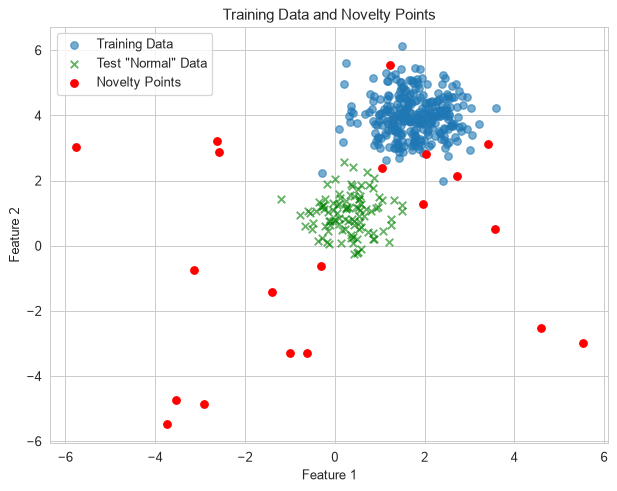

In [7]:
# Data latih: HANYA data normal
X_train, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

# Data uji: normal + novelty (kode asli buku)
X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
np.random.seed(2024)   # tambahan: seed agar novelty reprodusibel
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])

print('Pusat data latih          :', X_train.mean(axis=0).round(3))
print('Pusat data uji "normal"   :', X_test_normal.mean(axis=0).round(3))

plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], label='Training Data', alpha=0.6)
plt.scatter(X_test_normal[:, 0], X_test_normal[:, 1], color='green', marker='x', label='Test "Normal" Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Data latih berpusat di **(1.76, 3.98)**, tetapi data uji "normal" pada kode asli buku dibangkitkan dengan `center_box=(0, 1)` dan `random_state=42`, sehingga berpusat di **(0.30, 0.98)** — sekitar 3.3 satuan (≈5 simpangan baku) dari cluster latih. Pada plot terlihat silang hijau membentuk cluster terpisah di kiri bawah cluster latih.
- Dengan kata lain, menurut definisi novelty detection, "data uji normal" ini sebenarnya **juga novelty**: distribusinya berbeda dari data latih.

Jumlah support vector       : 17 (5.7% data latih)
Fraksi data LATIH di luar batas: 0.047 (<= nu = 0.05 secara asimtotik)
Uji normal ditandai novelty : 100 dari 100
Uji novelty ditandai novelty: 19 dari 20


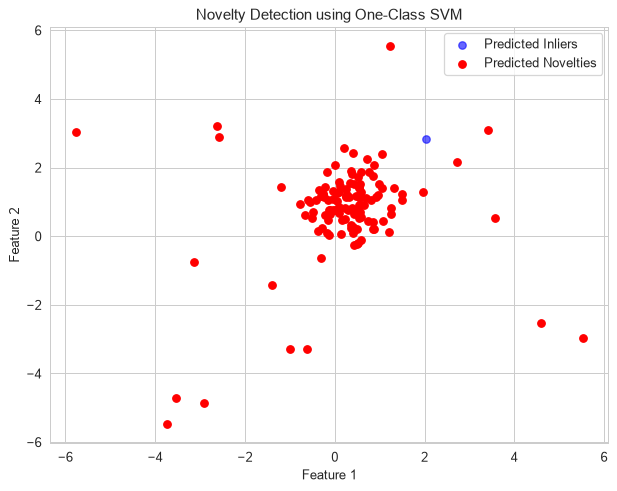

In [8]:
# One-Class SVM dilatih hanya pada data normal
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

# Prediksi pada data uji (+1 = inlier, -1 = novelty)
y_pred = model.predict(X_test)

print('Jumlah support vector       :', model.support_vectors_.shape[0], f'({model.support_vectors_.shape[0]/len(X_train):.1%} data latih)')
print('Fraksi data LATIH di luar batas:', f'{(model.predict(X_train) == -1).mean():.3f}', '(<= nu = 0.05 secara asimtotik)')
print('Uji normal ditandai novelty :', int((y_pred[:100] == -1).sum()), 'dari 100')
print('Uji novelty ditandai novelty:', int((y_pred[100:] == -1).sum()), 'dari 20')

# Catatan: warna di kode asli buku tertukar (inlier merah, novelty biru); di sini diperbaiki
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], color='blue', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred == -1, 0], X_test[y_pred == -1, 1], color='red', label='Predicted Novelties')
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Model memakai **17** support vector (5.7% data latih ≥ $\nu$ = 5%) dan **4.7%** data latih jatuh di luar batas (≤ $\nu$) — persis sesuai *ν-property*.
- Akibat masalah di atas, **seluruh 100** titik uji "normal" ditandai novelty, ditambah **19 dari 20** novelty sebenarnya. Secara teknis model bekerja benar (titik-titik itu memang di luar wilayah data latih), tetapi eksperimen buku tidak mengukur apa yang dimaksud. Pada kode asli warnanya juga tertukar (inlier merah, novelty biru), sehingga plotnya tampak "benar" padahal hampir semua titik adalah novelty; di sini warnanya sudah diperbaiki.

*Tambahan (bukan bagian dari notebook asli):* data uji normal dibangkitkan ulang dari distribusi yang sama dengan data latih (pusat cluster latih, std 0.6), lalu batas keputusan divisualisasikan untuk beberapa nilai $\nu$.

Uji normal ditandai novelty : 3 dari 100
Uji novelty ditandai novelty: 19 dari 20
ROC-AUC (-decision_function): 0.9955


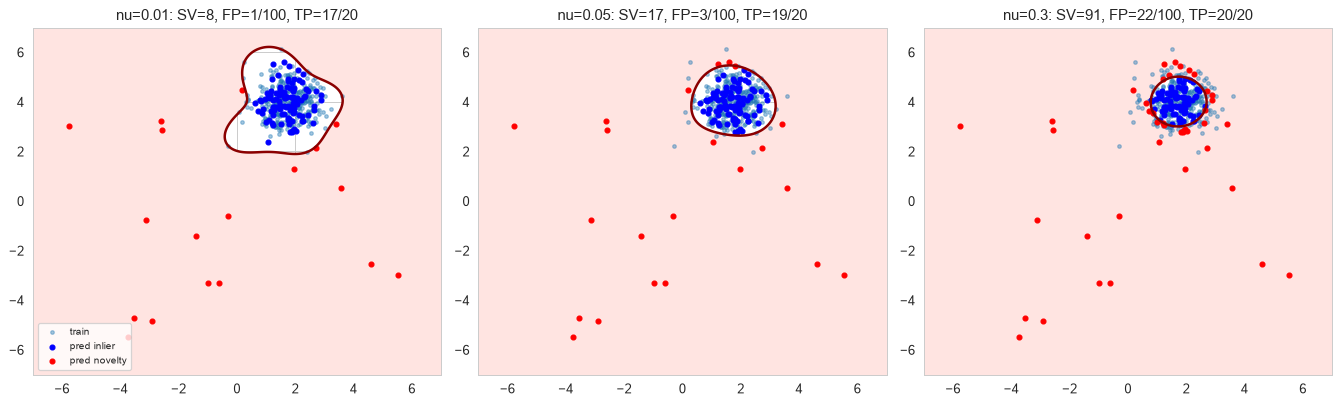

In [9]:
# Perbaikan: data uji normal diambil dari DISTRIBUSI YANG SAMA dengan data latih
center_train = X_train.mean(axis=0)
X_test_normal_ok, _ = make_blobs(n_samples=100, centers=[center_train], cluster_std=0.6, random_state=42)
X_test_ok = np.vstack([X_test_normal_ok, X_test_novelty])
y_test_ok = np.r_[np.zeros(100), np.ones(20)]   # 1 = novelty

y_pred_ok = model.predict(X_test_ok)
print('Uji normal ditandai novelty :', int((y_pred_ok[:100] == -1).sum()), 'dari 100')
print('Uji novelty ditandai novelty:', int((y_pred_ok[100:] == -1).sum()), 'dari 20')
print('ROC-AUC (-decision_function):', round(roc_auc_score(y_test_ok, -model.decision_function(X_test_ok)), 4))

# Batas keputusan One-Class SVM + pengaruh nu
xx, yy = np.meshgrid(np.linspace(-7, 7, 300), np.linspace(-7, 7, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, nu in zip(axes, [0.01, 0.05, 0.3]):
    m = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(X_train)
    Z = m.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[Z.min(), 0], colors='mistyrose')
    ax.contour(xx, yy, Z, levels=[0], colors='darkred', linewidths=2)
    p = m.predict(X_test_ok)
    ax.scatter(X_train[:, 0], X_train[:, 1], s=8, alpha=0.4, label='train')
    ax.scatter(X_test_ok[p == 1, 0], X_test_ok[p == 1, 1], c='blue', s=15, label='pred inlier')
    ax.scatter(X_test_ok[p == -1, 0], X_test_ok[p == -1, 1], c='red', s=15, label='pred novelty')
    fp = int((p[:100] == -1).sum()); tp = int((p[100:] == -1).sum())
    ax.set_title(f'nu={nu}: SV={len(m.support_vectors_)}, FP={fp}/100, TP={tp}/20')
    ax.set_xlim(-7, 7); ax.set_ylim(-7, 7)
axes[0].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi:**

- Setelah data uji normal diambil dari distribusi yang benar, hanya **3 dari 100** yang ditandai novelty (sesuai harapan ≈ $\nu$ = 5%), sementara **19 dari 20** novelty tetap terdeteksi, dengan ROC-AUC **0.996**. Inilah perilaku yang seharusnya ditunjukkan resep ini.
- Plot tiga panel memperlihatkan peran $\nu$: wilayah normal (area putih di dalam kontur merah) mengecil ketika $\nu$ naik, jumlah support vector bertambah (**8 → 17 → 91**), dan *false positive* pada data uji normal meningkat (**1 → 3 → 22** dari 100), sementara novelty yang tertangkap naik (**17 → 19 → 20** dari 20). Pada $\nu=0.01$ batasnya bahkan berbentuk tidak beraturan karena hanya ditentukan oleh 8 support vector. $\nu$ kecil memberi wilayah longgar (lebih sedikit alarm palsu, tetapi novelty yang dekat bisa lolos); $\nu$ besar memberi wilayah sempit (lebih sensitif, lebih banyak alarm palsu).

## 11.4 Local Outlier Factor (LOF)

**Teori:**

**Ide (Breunig et al., 2000).** Sebuah titik dianggap outlier bila **kepadatan lokalnya jauh lebih rendah daripada kepadatan tetangganya**. Karena perbandingannya relatif terhadap lingkungan sendiri, LOF dapat menemukan anomali **lokal**: titik yang tampak biasa secara global (mis. di antara dua cluster) tetapi janggal bila dibandingkan dengan cluster padat di dekatnya.

**Definisi langkah demi langkah** (dengan $k$ = `n_neighbors`, $N_k(p)$ = himpunan $k$ tetangga terdekat $p$):

1. **k-distance**: $d_k(o)$ = jarak dari $o$ ke tetangga ke-$k$-nya.
2. **Reachability distance**: $\operatorname{reach-dist}_k(p,o) = \max\{d_k(o),\ d(p,o)\}$. Bila $p$ sangat dekat dengan $o$, jaraknya "dibulatkan ke atas" menjadi $d_k(o)$, sehingga fluktuasi statistik dalam cluster padat teredam.
3. **Local reachability density**:
$$
\operatorname{lrd}_k(p) = \left(\frac{1}{|N_k(p)|}\sum_{o\in N_k(p)} \operatorname{reach-dist}_k(p,o)\right)^{-1}.
$$
4. **Local Outlier Factor**:
$$
\operatorname{LOF}_k(p) = \frac{1}{|N_k(p)|}\sum_{o\in N_k(p)} \frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)} .
$$

$\operatorname{LOF}\approx 1$: kepadatan setara tetangga (normal); $\operatorname{LOF} \gg 1$: jauh lebih jarang daripada tetangganya (outlier); $\operatorname{LOF}<1$: lebih padat (inti cluster).

**Di scikit-learn.** Atribut `negative_outlier_factor_` $= -\operatorname{LOF}$ untuk data latih. Dalam mode default (`novelty=False`) LOF hanya menyediakan `fit_predict` — tidak ada `predict`/`decision_function` untuk data baru, karena skor setiap titik latih dihitung tanpa menghitung dirinya sendiri sebagai tetangga. Dengan `novelty=True`, LOF menjadi detektor novelty: `predict`, `decision_function`, `score_samples` tersedia untuk data **baru** (dan tidak boleh dipakai pada data latih).

**Memilih $k$.** Dokumentasi scikit-learn menyarankan $k \approx 20$; $k$ harus lebih besar dari ukuran minimum sebuah cluster (agar cluster kecil tidak dianggap normal karena saling bertetangga) dan lebih kecil dari jumlah maksimum outlier yang mungkin bergerombol. Kompleksitasnya didominasi pencarian $k$-NN ($O(n\log n)$ dengan KD/Ball tree pada dimensi rendah, hingga $O(n^2)$ pada dimensi tinggi), dan karena berbasis jarak, fitur sebaiknya diskalakan.

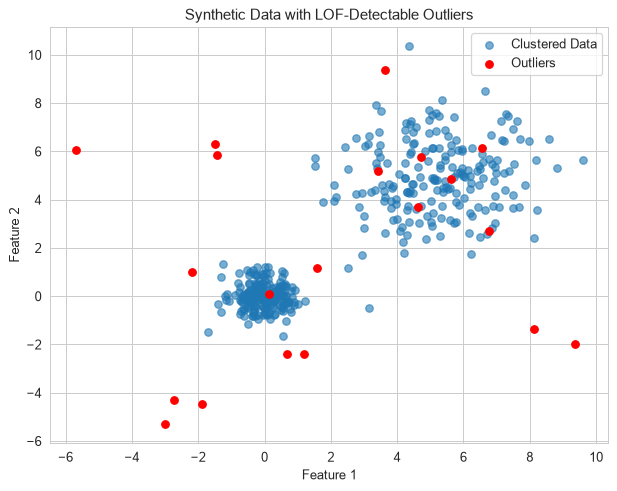

In [10]:
# Dua cluster dengan KEPADATAN BERBEDA + 20 titik noise
X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

Dataset sengaja dibuat dengan dua cluster berkepadatan sangat berbeda: cluster padat di (0, 0) dengan std 0.5 dan cluster renggang di (5, 5) dengan std 1.5 (200 titik masing-masing), ditambah 20 titik noise seragam pada $[-6,10]^2$. Beberapa titik noise jatuh **di dalam** cluster renggang sehingga secara alami tidak bisa dibedakan dari data normal.

Ambang LOF (= -offset_)          : 1.851
Jumlah titik ditandai outlier    : 21
...yang memang noise sintetis    : 13 dari 20
Median LOF inlier / noise        : 1.044 / 3.03
ROC-AUC (skor LOF kontinu)       : 0.7674


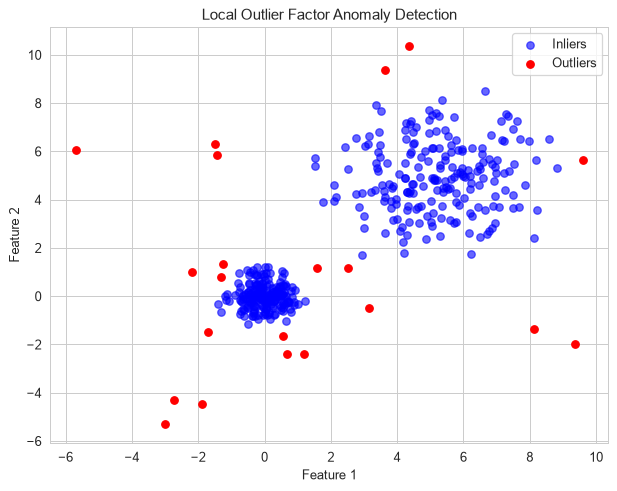

In [11]:
# LOF dengan k = 20 tetangga, 5% kontaminasi
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

y_true_4 = np.r_[np.zeros(len(X)), np.ones(len(outliers))]
lof_score = -lof.negative_outlier_factor_          # nilai LOF asli (~1 = normal)
flag = (y_pred == -1)
print('Ambang LOF (= -offset_)          :', round(-lof.offset_, 3))
print('Jumlah titik ditandai outlier    :', flag.sum())
print('...yang memang noise sintetis    :', int((flag & (y_true_4 == 1)).sum()), 'dari', len(outliers))
print('Median LOF inlier / noise        :', np.median(lof_score[y_true_4 == 0]).round(3), '/', np.median(lof_score[y_true_4 == 1]).round(3))
print('ROC-AUC (skor LOF kontinu)       :', round(roc_auc_score(y_true_4, lof_score), 4))

plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Median LOF inlier **1.044** (≈ 1, sesuai teori) sedangkan median LOF noise **3.03** — noise rata-rata tiga kali lebih "jarang" daripada lingkungannya. Ambang yang dipilih dari `contamination=0.05` adalah LOF > **1.85**.
- LOF menandai **21** titik dan **13 dari 20** noise tertangkap; ROC-AUC skor kontinu **0.767**. Angka ini jauh lebih rendah daripada 11.1–11.2 karena (a) sebagian noise jatuh di dalam/dekat cluster renggang (5, 5) sehingga LOF-nya ≈ 1, dan (b) titik-titik di tepi cluster renggang ikut mendapat LOF tinggi (8 *false positive*).
- Pada plot terlihat bahwa titik merah yang terdeteksi adalah noise yang terisolasi dari kedua cluster, dan beberapa titik tepi cluster renggang.

*Tambahan (bukan bagian dari notebook asli):* (a) visualisasi skor LOF, (b) sensitivitas terhadap `n_neighbors` dan perbandingan dengan Isolation Forest, (c) LOF dalam mode `novelty=True`.

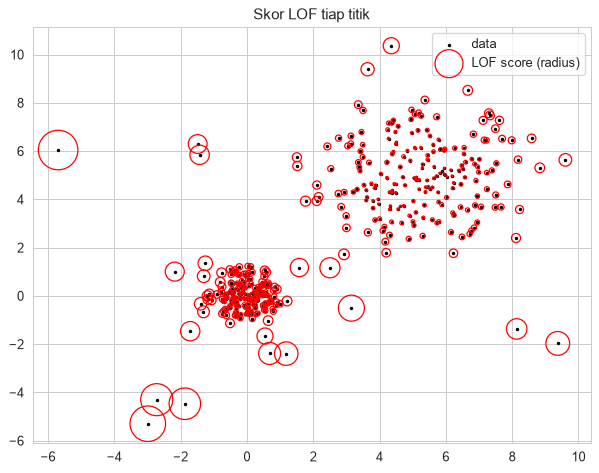

,ROC-AUC,noise terdeteksi (dari 20)
model,,
LOF k=5,0.8466,13
LOF k=10,0.8272,13
LOF k=20,0.7674,13
LOF k=35,0.7681,13
LOF k=50,0.7656,13
IsolationForest,0.8364,11


Novelty LOF untuk titik baru [[0.0, 0.0], [5.0, 5.0], [2.5, 2.5], [0.0, 3.0], [8.0, -4.0]]
  predict       : [ 1  1  1 -1 -1]
  LOF (score)   : [0.97 0.99 1.37 3.65 5.23]


In [12]:
# (a) Ukuran lingkaran sebanding dengan skor LOF
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[:, 0], X_with_outliers[:, 1], s=3, c='k', label='data')
r = (lof_score - lof_score.min()) / (lof_score.max() - lof_score.min())
plt.scatter(X_with_outliers[:, 0], X_with_outliers[:, 1], s=1000 * r, edgecolors='r',
            facecolors='none', label='LOF score (radius)')
plt.title('Skor LOF tiap titik'); plt.legend(); plt.show()

# (b) Sensitivitas terhadap n_neighbors, dan perbandingan dengan Isolation Forest (global)
rows = []
for k in [5, 10, 20, 35, 50]:
    l = LocalOutlierFactor(n_neighbors=k, contamination=0.05).fit(X_with_outliers)
    rows.append({'model': f'LOF k={k}',
                 'ROC-AUC': roc_auc_score(y_true_4, -l.negative_outlier_factor_),
                 'noise terdeteksi (dari 20)': int(((l.fit_predict(X_with_outliers) == -1) & (y_true_4 == 1)).sum())})
iso = IsolationForest(contamination=0.05, random_state=2024).fit(X_with_outliers)
rows.append({'model': 'IsolationForest',
             'ROC-AUC': roc_auc_score(y_true_4, -iso.score_samples(X_with_outliers)),
             'noise terdeteksi (dari 20)': int(((iso.predict(X_with_outliers) == -1) & (y_true_4 == 1)).sum())})
display(pd.DataFrame(rows).set_index('model').round(4))

# (c) LOF mode novelty: novelty=True mengaktifkan predict() untuk data baru
lof_nov = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.05).fit(X)
X_new = np.array([[0, 0], [5, 5], [2.5, 2.5], [0, 3], [8, -4]])
print('Novelty LOF untuk titik baru', X_new.tolist())
print('  predict       :', lof_nov.predict(X_new))
print('  LOF (score)   :', (-lof_nov.score_samples(X_new)).round(2))

**Interpretasi:**

- (a) Lingkaran besar (LOF tinggi) muncul pada noise yang terisolasi; titik di inti kedua cluster hampir tidak berlingkaran — meskipun cluster (5, 5) jauh lebih renggang. Ini menunjukkan sifat **lokal** LOF: kepadatan rendah tidak dihukum bila tetangganya juga renggang.
- (b) ROC-AUC tertinggi diperoleh dengan $k$ kecil (**0.847** untuk $k=5$), lalu turun ke ~**0.77** untuk $k\ge 20$, sementara jumlah noise yang tertangkap pada kuota 5% tetap 13. Isolation Forest memperoleh AUC **0.836** tetapi hanya menangkap **11** noise. Jadi pada data ini keunggulan LOF atas metode global tidak dramatis: sumber kesulitan utama adalah noise yang memang jatuh di dalam cluster, yang tidak dapat dideteksi metode apa pun.
- (c) Dengan `novelty=True`, LOF yang dilatih hanya pada data cluster dapat memprediksi titik baru: (0, 0) dan (5, 5) memperoleh LOF **0.97** dan **0.99** (inlier), titik tengah (2.5, 2.5) **1.37** (masih inlier), sedangkan (0, 3) dan (8, −4) memperoleh LOF **3.65** dan **5.23** dan diprediksi −1 (novelty). Perhatikan (0, 3) hanya berjarak 3 dari cluster padat tetapi dianggap novelty karena cluster di sekitarnya sangat rapat.

## 11.5 Evaluasi Model Deteksi Outlier

**Teori:**

**Mengapa akurasi menyesatkan.** Bila outlier hanya 9% data, detektor yang selalu menjawab "inlier" sudah mencapai akurasi 91%. Karena itu kita memakai metrik untuk kelas langka, dengan **outlier sebagai kelas positif** (label 1):

$$
\text{Precision} = \frac{TP}{TP+FP},\qquad \text{Recall} = \frac{TP}{TP+FN},\qquad F_1 = \frac{2\,PR}{P+R}.
$$

- **Confusion matrix** memperlihatkan keempat sel (TN, FP, FN, TP). Dalam aplikasi nyata biaya FP (alarm palsu) dan FN (anomali lolos) biasanya sangat berbeda.
- **Metrik berbasis ambang vs berbasis skor.** Precision/recall/F1 bergantung pada ambang (di sini `contamination`). **ROC-AUC** dan **PR-AUC (average precision)** dihitung dari skor kontinu dan mengukur kualitas *peringkat*: ROC-AUC = peluang outlier acak mendapat skor anomali lebih tinggi daripada inlier acak, $\Pr(s(x^+)>s(x^-))$. Pada data sangat tidak seimbang, PR-AUC lebih informatif karena baseline-nya adalah proporsi positif (bukan 0.5).
- **Arah skor sangat penting.** `decision_function` dan `score_samples` di scikit-learn bernilai **besar untuk inlier**. Bila label positif adalah outlier, skor yang diberikan ke `roc_auc_score` harus **dinegasikan**; jika tidak, AUC yang diperoleh adalah $1-\text{AUC}$ yang benar.
- **Tanpa label** (kasus umum): validasi oleh pakar domain, stabilitas peringkat antar-subsampel/seed, kesepakatan beberapa detektor, metrik *Excess-Mass/Mass-Volume* curve, atau galat rekonstruksi (autoencoder/PCA).

Proporsi outlier sebenarnya: 0.0909


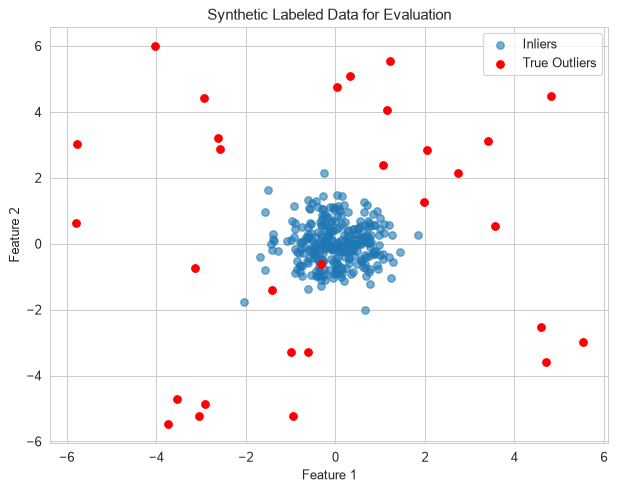

In [13]:
# Dataset berlabel: 300 inlier (0) + 30 outlier (1)
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
np.random.seed(2024)   # tambahan: seed agar hasil reprodusibel
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))  # 0 = inlier, 1 = outlier
print('Proporsi outlier sebenarnya:', round(y_true.mean(), 4))

plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0], X[y_true == 0][:, 1], label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0], X[y_true == 1][:, 1], color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

Dataset berisi 300 inlier dan 30 outlier, sehingga proporsi outlier sebenarnya **9.09%** — inilah alasan buku memakai `contamination=0.09`. (Kode asli tidak memberi seed untuk outlier; di sini ditambahkan `np.random.seed(2024)` agar hasilnya reprodusibel.)

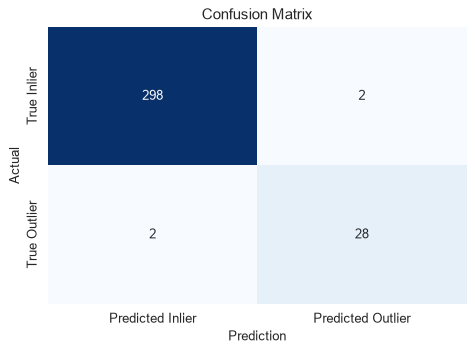

,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


ROC-AUC Score (kode asli, decision_function)  : 0.0214
ROC-AUC Score (benar, -decision_function)     : 0.9786
Average Precision (PR-AUC, -decision_function): 0.9607


In [14]:
# Fit Isolation Forest dan evaluasi
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(y_pred == 1, 0, 1)  # ubah ke 0 = inlier, 1 = outlier

cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

# PERBAIKAN: decision_function bernilai BESAR untuk inlier, jadi skor outlier = -decision_function.
# Kode asli buku memakai decision_function langsung -> AUC terbalik (= 1 - AUC yang benar).
print("ROC-AUC Score (kode asli, decision_function)  :", round(roc_auc_score(y_true, model.decision_function(X)), 4))
print("ROC-AUC Score (benar, -decision_function)     :", round(roc_auc_score(y_true, -model.decision_function(X)), 4))
print("Average Precision (PR-AUC, -decision_function):", round(average_precision_score(y_true, -model.decision_function(X)), 4))

**Interpretasi:**

- Confusion matrix: **298 TN, 2 FP, 2 FN, 28 TP**. Karena kuota (`contamination=0.09` → 30 titik) sama dengan jumlah outlier sebenarnya, jumlah FP pasti sama dengan FN, sehingga precision = recall = F1 = **0.933** untuk kelas outlier; kelas inlier 0.993, akurasi 0.988.
- **Koreksi ROC-AUC:** kode asli buku menghitung `roc_auc_score(y_true, model.decision_function(X))` dan mendapat **0.021** — hampir nol, yang seolah berarti model sangat buruk. Penyebabnya adalah arah skor (decision_function besar = inlier). Dengan skor yang dinegasikan, ROC-AUC = **0.979** ($=1-0.021$) dan PR-AUC = **0.961** (baseline acak hanya 0.091). Detektor ini sebenarnya sangat baik.

*Tambahan (bukan bagian dari notebook asli):* membandingkan empat detektor (termasuk `EllipticEnvelope`, estimator kovarians robust MCD yang mengasumsikan data normal berdistribusi Gaussian) pada data berlabel yang sama.

In [15]:
# Membandingkan beberapa detektor pada data berlabel yang sama (skor kontinu, bebas ambang)
detectors = {
    'IsolationForest': IsolationForest(contamination=0.09, random_state=2024),
    'LOF (k=20)': LocalOutlierFactor(n_neighbors=20, contamination=0.09),
    'OneClassSVM (nu=0.09)': OneClassSVM(kernel='rbf', gamma='scale', nu=0.09),
    'EllipticEnvelope': EllipticEnvelope(contamination=0.09, random_state=2024),
}
rows = []
for name, det in detectors.items():
    if isinstance(det, LocalOutlierFactor):
        pred = det.fit_predict(X)
        score = -det.negative_outlier_factor_
    else:
        pred = det.fit(X).predict(X)
        score = -det.decision_function(X)
    pb = (pred == -1).astype(int)
    tp = int(((pb == 1) & (y_true == 1)).sum())
    rows.append({'model': name,
                 'precision': tp / pb.sum(),
                 'recall': tp / y_true.sum(),
                 'ROC-AUC': roc_auc_score(y_true, score),
                 'PR-AUC': average_precision_score(y_true, score)})
display(pd.DataFrame(rows).set_index('model').round(3))

,precision,recall,ROC-AUC,PR-AUC
model,,,,
IsolationForest,0.933,0.933,0.979,0.961
LOF (k=20),0.933,0.933,0.971,0.963
OneClassSVM (nu=0.09),0.742,0.767,0.946,0.817
EllipticEnvelope,0.933,0.933,0.980,0.964


**Interpretasi:**

- Isolation Forest (AUC 0.979), LOF (0.971) dan EllipticEnvelope (**0.980**) setara dan sama-sama mencapai precision/recall 0.933 pada kuota 9%. EllipticEnvelope sedikit unggul karena asumsinya (satu cluster Gaussian) persis sesuai dengan cara data dibangkitkan — pada data multimodal atau non-Gaussian ia akan gagal.
- One-Class SVM tertinggal (AUC 0.946, PR-AUC 0.817, precision 0.742). OCSVM dirancang untuk novelty detection pada data bersih; di sini ia dilatih pada data yang sudah tercemar 9% outlier, sehingga sebagian outlier ikut menjadi support vector dan "membengkokkan" batas.

## 11.6 Penanganan Outlier yang Terdeteksi

**Teori:**

Setelah outlier ditemukan, keputusan berikutnya bergantung pada **penyebabnya**:

| Penyebab | Contoh | Tindakan wajar |
|---|---|---|
| Kesalahan data | salah ketik, sensor rusak, unit salah | perbaiki atau buang |
| Variasi alami yang ekstrem | pelanggan sangat kaya | pertahankan; pakai model/loss robust atau transformasi |
| Fenomena yang dicari | fraud, intrusi, kerusakan | pertahankan dan modelkan secara khusus |

**Strategi umum:**

1. **Removal (trimming):** hapus baris outlier. Sederhana, tetapi mengurangi ukuran sampel dan berbahaya bila outlier sebenarnya informatif; juga mengubah distribusi target bila outlier terkait label.
2. **Replacement/imputasi:** ganti dengan statistik pusat (median lebih robust daripada mean) atau imputasi berbasis model (`KNNImputer`, `IterativeImputer`). Ukuran sampel tetap, tetapi variansi mengecil secara artifisial dan muncul "tumpukan" nilai identik.
3. **Capping/winsorization:** potong setiap fitur pada persentil bawah $q_\alpha$ dan atas $q_{1-\alpha}$: $x' = \min(\max(x, q_\alpha), q_{1-\alpha})$. Mempertahankan urutan (ordinal) dan semua baris; bersifat **univariat**, sehingga juga memotong titik normal yang ekstrem pada satu fitur dan tidak menangkap outlier multivariat.
4. **Flagging:** pertahankan nilai asli dan tambahkan fitur indikator `is_outlier` (atau skor anomali kontinu) agar model hilir dapat mempelajari perilaku yang berbeda.
5. **Transformasi & model robust** (alternatif): log/Box-Cox, `RobustScaler` (median & IQR), `QuantileTransformer`, atau model dengan loss robust (`HuberRegressor`, `RANSACRegressor`), serta model berbasis pohon yang relatif tidak peka outlier pada fitur.

**Hindari kebocoran data:** detektor, batas persentil, dan median harus dipelajari dari **data latih saja** (idealnya di dalam `Pipeline`), lalu diterapkan ke data uji. Jangan membuang outlier dari data uji hanya agar metrik terlihat bagus.

In [16]:
# Dataset dan deteksi outlier dengan Isolation Forest
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
np.random.seed(2024)   # tambahan: seed agar hasil reprodusibel
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1
print('Jumlah outlier terdeteksi:', outlier_mask.sum(), 'dari', len(X))

Jumlah outlier terdeteksi: 30 dari 330


**Interpretasi:**

Dengan `contamination=0.09`, Isolation Forest menandai **30 dari 330** titik — data dan model identik dengan 11.5, sehingga 28 di antaranya outlier sebenarnya dan 2 adalah inlier di tepi cluster.

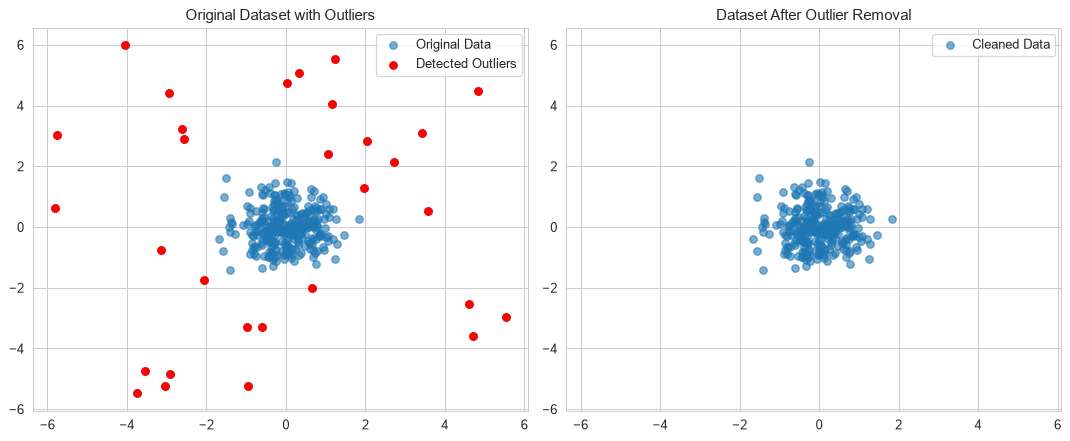

In [17]:
# 1) Removal: buang outlier
X_cleaned = X[~outlier_mask]

# 2) Replacement: ganti outlier dengan median fitur (dihitung dari inlier)
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# 3) Capping / winsorization pada persentil 5% dan 95%
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualisasi data asli vs data bersih dengan sumbu yang sama
plt.figure(figsize=(12, 5))

ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1], label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)

ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())

plt.tight_layout()
plt.show()

**Interpretasi:**

Panel kiri memperlihatkan 30 titik merah yang terdeteksi di sekeliling cluster; panel kanan (dengan sumbu yang sama) memperlihatkan data setelah *removal*: tersisa 300 titik yang hanya menempati wilayah sekitar $[-2,2]^2$. Kode asli juga menghitung `X_replaced` dan `X_capped`, tetapi tidak menampilkannya; sel berikut membandingkan keempat strategi secara kuantitatif.

*Tambahan (bukan bagian dari notebook asli):* strategi **flagging**, statistik ringkas tiap strategi, dan visualisasi hasil replacement/capping.

Statistik feature1 per strategi:


,n,mean,std,min,max
strategi,,,,,
Asli,330,-0.022,1.129,-5.802,5.531
Removal,300,-0.001,0.611,-1.675,1.842
Replacement (median),330,-0.003,0.583,-1.675,1.842
Capping 5%-95%,330,-0.017,0.675,-1.423,1.177
Inlier sebenarnya (acuan),300,-0.000,0.618,-2.052,1.842


Batas capping feature1: [-1.423, 1.177]


,feature1,feature2,is_outlier,anomaly_score
311,5.531,-2.979,1,0.210
329,-4.036,5.997,1,0.206
328,4.825,4.488,1,0.196
305,-5.771,3.031,1,0.191
301,-3.742,-5.474,1,0.184


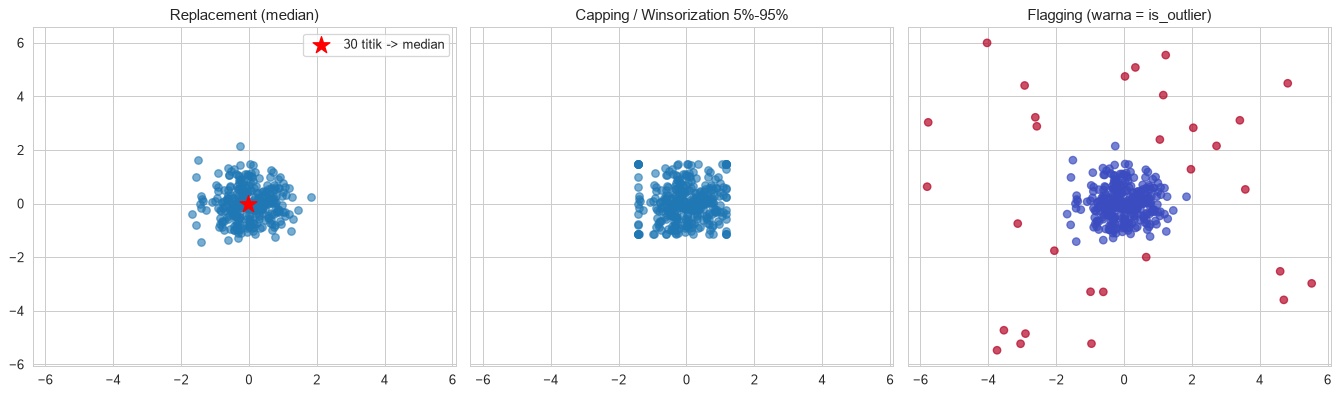

In [18]:
# 4) Flagging: simpan outlier tetapi tambahkan kolom indikator
X_flagged = X_df.copy()
X_flagged['is_outlier'] = outlier_mask.astype(int)
X_flagged['anomaly_score'] = -model.decision_function(X)

# Ringkasan statistik tiap strategi untuk feature1
def ringkas(arr, nama):
    a = np.asarray(arr)
    return {'strategi': nama, 'n': len(a), 'mean': a.mean(), 'std': a.std(ddof=1),
            'min': a.min(), 'max': a.max()}

tabel = pd.DataFrame([
    ringkas(X[:, 0], 'Asli'),
    ringkas(X_cleaned[:, 0], 'Removal'),
    ringkas(X_replaced[:, 0], 'Replacement (median)'),
    ringkas(X_capped['feature1'], 'Capping 5%-95%'),
    ringkas(X_inliers[:, 0], 'Inlier sebenarnya (acuan)'),
]).set_index('strategi')
print('Statistik feature1 per strategi:')
display(tabel.round(3))
print('Batas capping feature1:', X_df['feature1'].quantile([0.05, 0.95]).round(3).tolist())
display(X_flagged.sort_values('anomaly_score', ascending=False).head(5).round(3))

# Visualisasi tiga strategi yang mempertahankan/mengubah titik
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
axes[0].scatter(X_replaced[:, 0], X_replaced[:, 1], alpha=0.6)
axes[0].scatter(*median_vals, c='red', marker='*', s=200, label=f'{outlier_mask.sum()} titik -> median')
axes[0].set_title('Replacement (median)'); axes[0].legend()
axes[1].scatter(X_capped['feature1'], X_capped['feature2'], alpha=0.6)
axes[1].set_title('Capping / Winsorization 5%-95%')
axes[2].scatter(X[:, 0], X[:, 1], c=outlier_mask, cmap='coolwarm', alpha=0.7)
axes[2].set_title('Flagging (warna = is_outlier)')
plt.tight_layout(); plt.show()

**Interpretasi:**

- Data asli: std `feature1` = **1.129** dengan rentang −5.80 s.d. 5.53, jauh lebih lebar daripada inlier sebenarnya (std **0.618**).
- **Removal** mengembalikan std ke **0.611** (rentang −1.68 s.d. 1.84), sangat dekat dengan acuan, dengan kehilangan 30 baris.
- **Replacement (median)** mempertahankan 330 baris tetapi std turun ke **0.583**, *lebih kecil* dari acuan — efek samping imputasi konstanta: 30 titik menumpuk di satu titik median (bintang merah pada plot kiri).
- **Capping 5%–95%** memotong `feature1` ke $[-1.42, 1.18]$. Std **0.675** masih sedikit di atas acuan karena outlier tidak dibuang melainkan dipindahkan ke tepi, sehingga plot tengah tampak berupa "kotak" dengan titik-titik menempel di batas. Selain itu batas persentil ini juga memotong titik **normal** di ekor cluster (min inlier −2.05 menjadi −1.42) — kelemahan pendekatan univariat.
- **Flagging** mempertahankan semua nilai dan menambahkan kolom `is_outlier` dan `anomaly_score`; lima titik dengan skor tertinggi (≈0.18–0.21) semuanya berada di sudut-sudut kotak $[-6,6]^2$.

## 11.7 Memilih Teknik Deteksi yang Tepat

**Teori:**

Tidak ada detektor yang selalu terbaik ("no free lunch"); setiap metode membawa definisi "normal" yang berbeda:

| Metode | Definisi "normal" | Kekuatan | Kelemahan |
|---|---|---|---|
| **Isolation Forest** | sulit diisolasi oleh potongan acak | cepat, skala ke data besar & dimensi tinggi, tidak perlu scaling | global; artefak sejajar sumbu |
| **LOF** | kepadatan setara dengan tetangganya | anomali lokal, cluster berbeda kepadatan | butuh $k$-NN (mahal untuk $n$ besar), peka skala & pilihan $k$; prediksi data baru hanya dengan `novelty=True` |
| **One-Class SVM** | berada di dalam batas kernel yang dipelajari | batas non-linear fleksibel, cocok untuk novelty | $O(n^2)$+, sangat peka skala, $\gamma$, $\nu$; buruk bila data latih tercemar |
| **EllipticEnvelope** | jarak Mahalanobis robust kecil | sangat baik untuk data unimodal Gaussian | gagal pada data multimodal/non-Gaussian |

**Panduan praktis:**

1. Apakah data latih bersih? Ya → novelty detection (OCSVM, LOF `novelty=True`); tidak → outlier detection (IF, LOF, EllipticEnvelope).
2. Data besar/berdimensi tinggi → mulai dengan Isolation Forest (atau `SGDOneClassSVM`).
3. Cluster dengan kepadatan berbeda / anomali lokal → LOF.
4. Data kira-kira Gaussian unimodal → EllipticEnvelope sebagai baseline.
5. Selalu: skalakan fitur untuk metode berbasis jarak/kernel, laporkan metrik berbasis skor (ROC-AUC/PR-AUC) bila ada label, dan coba beberapa detektor (ensemble skor yang dinormalisasi sering lebih stabil).

In [19]:
# Tabel perbandingan metode (dari buku)
data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}

summary_df = pd.DataFrame(data)
summary_df = summary_df.set_index("Algorithm")   # inplace=True deprecated di pandas 3.1
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


**Interpretasi:**

Tabel dari buku merangkum perbedaan utama. Dua catatan: (1) kolom "Supports New Predictions = No" untuk LOF berlaku pada mode default; dengan `novelty=True` LOF bisa memprediksi data baru (lihat 11.4c); (2) "Learns From Unlabeled Data = No (novelty only)" untuk OCSVM maksudnya OCSVM tetap *unsupervised* (tidak perlu label), tetapi mengasumsikan data latih hanya berisi data normal. (Penyesuaian: `set_index(..., inplace=True)` diganti assignment karena argumen `inplace` sudah *deprecated* di pandas 3.1.)

In [20]:
# Data besar & berdimensi tinggi -> Isolation Forest
model_if = IsolationForest(contamination=0.1, random_state=2024)

# Cluster dengan kepadatan berbeda -> Local Outlier Factor
model_lof = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# Latih hanya pada data normal, deteksi titik baru -> One-Class SVM
model_ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)

for m in [model_if, model_lof, model_ocsvm]:
    print(f'{type(m).__name__:20s} punya predict()? {hasattr(m, "predict")}')
print('LOF dengan novelty=True punya predict()?',
      hasattr(LocalOutlierFactor(novelty=True), 'predict'))

IsolationForest      punya predict()? True
LocalOutlierFactor   punya predict()? False
OneClassSVM          punya predict()? True
LOF dengan novelty=True punya predict()? True


**Interpretasi:**

Sel ini (sesuai buku) hanya menginstansiasi ketiga model sesuai skenario. Pengecekan `hasattr` menegaskan perbedaan API: `IsolationForest` dan `OneClassSVM` memiliki `predict()`, sedangkan `LocalOutlierFactor` default **tidak** (hanya `fit_predict`), kecuali dibuat dengan `novelty=True`.

*Tambahan (bukan bagian dari notebook asli):* eksperimen kecil untuk menguji klaim tabel tentang skalabilitas dan dimensi tinggi (satu cluster Gaussian + 2% outlier seragam, parameter default).

In [21]:
# Eksperimen kecil: skalabilitas & dimensi tinggi (data sintetis make_blobs, 1 cluster + 2% outlier)
import time

def make_data(n, d, seed=0):
    Xn, _ = make_blobs(n_samples=n, centers=[np.zeros(d)], cluster_std=1.0, random_state=seed)
    rng = np.random.default_rng(seed)
    n_out = int(0.02 * n)
    Xo = rng.uniform(-6, 6, size=(n_out, d))
    return np.vstack([Xn, Xo]), np.r_[np.zeros(n), np.ones(n_out)]

rows = []
for n, d in [(2000, 2), (2000, 50), (10000, 2)]:
    Xs, ys = make_data(n, d)
    for name, det in [('IsolationForest', IsolationForest(random_state=0)),
                      ('LOF', LocalOutlierFactor(n_neighbors=20)),
                      ('OneClassSVM', OneClassSVM(gamma='scale', nu=0.02))]:
        t0 = time.perf_counter()
        if name == 'LOF':
            det.fit(Xs); score = -det.negative_outlier_factor_
        else:
            score = -det.fit(Xs).decision_function(Xs)
        rows.append({'n': n, 'd': d, 'model': name,
                     'waktu (s)': time.perf_counter() - t0,
                     'ROC-AUC': roc_auc_score(ys, score)})
res = pd.DataFrame(rows)
display(res.pivot_table(index=['n', 'd'], columns='model', values=['waktu (s)', 'ROC-AUC']).round(3))

ROC-AUC                          waktu (s)                   
model    IsolationForest    LOF OneClassSVM IsolationForest    LOF OneClassSVM
n     d                                                                       
2000  2            0.973  0.968       0.778           0.576  0.044       0.065
      50           1.000  1.000       0.967           0.607  1.775       0.096
10000 2            0.960  0.914       0.773           0.641  0.135       1.920

**Interpretasi:**

- **Kualitas skor:** Isolation Forest paling konsisten (AUC 0.973 / 1.000 / 0.960). LOF hampir setara pada $n=2000$ (0.968) tetapi turun pada $n=10000$ (0.914) — dengan $k=20$ tetap, lingkungan menjadi relatif lebih kecil saat data makin padat. One-Class SVM dengan default `gamma='scale'` justru paling lemah pada 2 dimensi (≈0.78), menegaskan bahwa OCSVM perlu dituning ($\gamma$, $\nu$) dan tidak ideal untuk data latih yang tercemar.
- **Dimensi tinggi (d=50):** semua metode membaik (IF dan LOF mencapai 1.000) karena outlier seragam di kotak 50-dimensi sangat jauh dari cluster — pada data nyata anomali berdimensi tinggi biasanya jauh lebih halus, dan di situlah metode berbasis jarak mulai menderita.
- **Waktu** (angka bervariasi antar-run; pada run ini): waktu IF hampir konstan (~0.6 s) di ketiga skenario karena setiap pohon hanya memakai subsampel 256 (biaya utamanya adalah overhead tetap membangun 100 pohon). LOF sangat cepat pada 2 dimensi (0.04–0.14 s) tetapi melonjak ke **1.8 s** pada $d=50$, karena KD/Ball tree kehilangan efisiensinya di dimensi tinggi dan pencarian tetangga mendekati *brute force*. Waktu OCSVM tumbuh paling cepat terhadap $n$ (0.07 s → **1.9 s** saat $n$ naik 5×), sesuai kompleksitas superlinear-nya. Jadi klaim tabel buku (IF paling skalabel; LOF lemah di dimensi tinggi; OCSVM tidak skala ke $n$ besar) mulai terlihat bahkan pada data kecil ini.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter beserta solusinya (dari notebook *Exercise Solutions*). Walaupun judul latihannya menyebut "credit card", "network intrusion", dan "manufacturing sensor", solusi resmi memakai data sintetis (`make_blobs` / distribusi normal & seragam), sehingga di sini juga demikian. Seed `np.random.seed(2024)` ditambahkan di tiap latihan agar hasil reprodusibel.

### Exercise 1: Applying Isolation Forest to a Real-World Dataset

In [22]:
# Exercise 1: Isolation Forest + StandardScaler
np.random.seed(2024)   # tambahan: seed agar hasil reprodusibel
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X_scaled)
y_pred = model.predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

print("Exercise 1 Results:")
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'})
)
display(styled_report)
print('ROC-AUC (-decision_function):', round(roc_auc_score(y_true, -model.decision_function(X_scaled)), 4))

Exercise 1 Results:


,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


ROC-AUC (-decision_function): 0.9786


**Interpretasi:**

- Hasilnya **identik** dengan 11.5: precision = recall = F1 = **0.933** untuk outlier (28 dari 30), akurasi 0.988, ROC-AUC **0.979**. Ini bukan kebetulan: Isolation Forest memilih ambang potongan secara seragam di antara min dan max fitur pada setiap node, sehingga transformasi afin per fitur seperti `StandardScaler` hanya "meregangkan" pohon tanpa mengubah partisinya (dengan `random_state` yang sama).
- Pelajaran: scaling tidak diperlukan untuk Isolation Forest, tetapi wajib untuk LOF dan One-Class SVM.

### Exercise 2: Using LOF on a Network Intrusion Dataset

Exercise 2 Results:


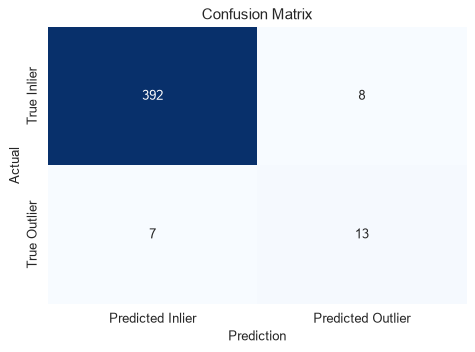

,precision,recall,f1-score,support
0,0.982,0.980,0.981,400
1,0.619,0.650,0.634,20
accuracy,0.964,0.964,0.964,1
macro avg,0.801,0.815,0.808,420
weighted avg,0.965,0.964,0.965,420


ROC-AUC (skor LOF): 0.7666


In [23]:
# Exercise 2: LOF pada data "network" berkluster + noise
np.random.seed(2024)   # tambahan: seed agar hasil reprodusibel
X_clustered, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
X_noise = np.random.uniform(low=-6, high=10, size=(20, 2))
X_combined = np.vstack([X_clustered, X_noise])
y_combined = np.array([0] * 400 + [1] * 20)

X_scaled = scaler.fit_transform(X_combined)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

print("Exercise 2 Results:")
cm = confusion_matrix(y_combined, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_combined, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'})
)
display(styled_report)
print('ROC-AUC (skor LOF):', round(roc_auc_score(y_combined, -lof.negative_outlier_factor_), 4))

**Interpretasi:**

- Confusion matrix: **392 TN, 8 FP, 7 FN, 13 TP**. Untuk kelas outlier precision **0.619**, recall **0.650**, F1 **0.634**; akurasi 0.964 terlihat tinggi tetapi hanya karena 95% data adalah inlier (contoh nyata mengapa akurasi menyesatkan).
- ROC-AUC skor LOF **0.767**, praktis sama dengan versi tanpa scaling di 11.4 (0.767): kedua fitur sudah berskala serupa, sehingga `StandardScaler` hampir tidak mengubah struktur tetangga. Kinerja yang sedang ini kembali disebabkan noise seragam yang jatuh di dalam cluster renggang (5, 5).

### Exercise 3: One-Class SVM for Manufacturing Sensor Data

Data uji normal ditandai novelty : 9 dari 60
Novelty ditandai novelty         : 26 dari 30
ROC-AUC (-decision_function)     : 0.8933


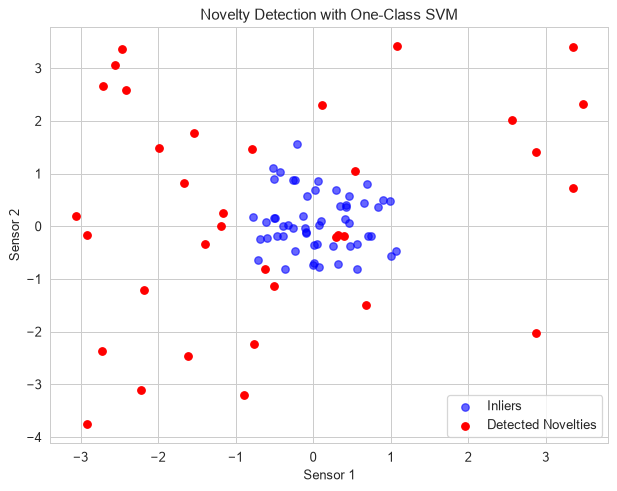

In [24]:
# Exercise 3: One-Class SVM untuk data sensor manufaktur (novelty detection)
np.random.seed(2024)   # tambahan: seed agar hasil reprodusibel
X_normal = np.random.normal(loc=0.0, scale=0.5, size=(300, 2))
X_novelty = np.random.uniform(low=-4, high=4, size=(30, 2))
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=2024)
X_eval = np.vstack([X_test, X_novelty])
y_eval = np.r_[np.zeros(len(X_test)), np.ones(len(X_novelty))]

svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
svm_model.fit(X_train)
y_pred = svm_model.predict(X_eval)

print('Data uji normal ditandai novelty :', int((y_pred[:len(X_test)] == -1).sum()), 'dari', len(X_test))
print('Novelty ditandai novelty         :', int((y_pred[len(X_test):] == -1).sum()), 'dari', len(X_novelty))
print('ROC-AUC (-decision_function)     :', round(roc_auc_score(y_eval, -svm_model.decision_function(X_eval)), 4))

plt.figure(figsize=(8, 6))
plt.scatter(X_eval[y_pred == 1][:, 0], X_eval[y_pred == 1][:, 1], color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_eval[y_pred == -1][:, 0], X_eval[y_pred == -1][:, 1], color='red', label='Detected Novelties')
plt.title("Novelty Detection with One-Class SVM")
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**

- Model dilatih pada 240 pembacaan sensor normal ($\mathcal N(0, 0.5^2)$ per sensor) dan diuji pada 60 pembacaan normal yang belum dilihat + 30 novelty seragam di $[-4,4]^2$.
- **26 dari 30** novelty terdeteksi (recall 0.87), tetapi **9 dari 60** data normal ikut ditandai (15% alarm palsu, jauh di atas $\nu$ = 5%). Dengan hanya 240 titik latih, batas RBF cenderung sedikit terlalu ketat di sekitar titik latih, sehingga titik normal baru di ekor distribusi jatuh di luar batas. ROC-AUC **0.893**.
- Empat novelty yang lolos adalah titik seragam yang kebetulan jatuh dekat pusat (0, 0) — secara fisik pembacaan tersebut memang tidak bisa dibedakan dari kondisi normal. Menurunkan $\gamma$ atau $\nu$ akan mengurangi alarm palsu dengan risiko melewatkan lebih banyak novelty.

## Ringkasan Chapter 11

1. **Outlier vs novelty detection.** Outlier detection mencari titik janggal di data latih yang sudah tercemar (IsolationForest, LOF, EllipticEnvelope); novelty detection belajar dari data bersih lalu menilai data baru (OneClassSVM, LOF `novelty=True`). Semua detektor scikit-learn mengembalikan +1/−1, dan `contamination`/`nu` hanya menggeser ambang skor. Pada data contoh, LOF (kuota 5%) menandai 16 titik dengan 15 di antaranya outlier sebenarnya.
2. **Isolation Forest** mengisolasi titik dengan potongan acak; skor $s(x)=2^{-\mathbb E[h(x)]/c(\psi)}$ mendekati 1 untuk anomali. Ia cepat (subsampel 256), tidak perlu scaling (hasil Exercise 1 identik dengan/ tanpa `StandardScaler`), dan mencapai ROC-AUC 0.98–0.99 pada data satu cluster.
3. **One-Class SVM** memisahkan data dari titik asal di ruang kernel; $\nu$ membatasi fraksi titik latih di luar batas (terbukti: 4.7% ≤ 5%). Asumsi kuncinya adalah data uji normal berasal dari distribusi yang sama — kode asli buku melanggarnya sehingga 100/100 titik "normal" ditandai novelty; setelah diperbaiki hanya 3/100 dengan 19/20 novelty terdeteksi (AUC 0.996).
4. **LOF** membandingkan kepadatan lokal sebuah titik dengan tetangganya (LOF ≈ 1 normal, ≫ 1 outlier), sehingga mampu menangani cluster berkepadatan berbeda. Pada data dua cluster + noise, median LOF inlier 1.04 vs noise 3.03, tetapi noise yang jatuh di dalam cluster renggang membatasi ROC-AUC ke ~0.77–0.85 (tergantung $k$).
5. **Evaluasi:** gunakan precision, recall, F1, confusion matrix, serta metrik berbasis skor ROC-AUC/PR-AUC — dan pastikan arah skornya benar. Kode asli buku melaporkan ROC-AUC 0.021 karena memakai `decision_function` tanpa dinegasikan; nilai yang benar adalah 0.979 (PR-AUC 0.961).
6. **Penanganan outlier** (removal, replacement, capping, flagging) harus disesuaikan dengan penyebabnya. Removal mengembalikan std fitur ke ~0.61 (acuan 0.62), replacement median mengecilkan variansi secara artifisial (0.58), dan winsorization univariat juga memotong titik normal di ekor. Semua statistik/detektor harus dipelajari dari data latih saja.
7. **Memilih metode:** mulai dengan Isolation Forest untuk data besar/umum, LOF untuk anomali lokal, One-Class SVM untuk novelty dengan data latih bersih (setelah scaling dan tuning $\gamma$, $\nu$), dan EllipticEnvelope untuk data Gaussian unimodal. Eksperimen kecil menunjukkan IF paling konsisten, sedangkan OCSVM default paling peka terhadap tuning dan waktu latihnya tumbuh paling cepat terhadap $n$.